In [1607]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error         # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler        # 정규화 클래스


In [1592]:
df = pd.read_csv('data/perch_full.csv')
df.shape

(56, 3)

In [1593]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [1594]:
# 학습데이터 , 테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)

In [1595]:
# 특성값을 추가
# length , height , width
# length**2 , height**2 , width**2
poly = PolynomialFeatures(degree=4,include_bias=False)


In [1596]:
# # 다항특성추가 - PolynomialFeatures
# poly = PolynomialFeatures(degree=2,include_bias=False)
# # poly = PolynomialFeatures(degree=2)
# poly.fit([[2,3]])
# train_poly = poly.transform([[2,3]])
# train_poly

In [1597]:
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
print(train_poly.shape)


(42, 34)


In [1598]:
train_data[:2]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [1599]:
train_poly[:2]

array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, 3.84160000e+02,
        1.00744000e+02, 5.95840000e+01, 2.64196000e+01, 1.56256000e+01,
        9.24160000e+00, 7.52953600e+03, 1.97458240e+03, 1.16784640e+03,
        5.17824160e+02, 3.06261760e+02, 1.81135360e+02, 1.35796744e+02,
        8.03155840e+01, 4.75018240e+01, 2.80944640e+01, 1.47578906e+05,
        3.87018150e+04, 2.28897894e+04, 1.01493535e+04, 6.00273050e+03,
        3.55025306e+03, 2.66161618e+03, 1.57418545e+03, 9.31035750e+02,
        5.50651494e+02, 6.97995264e+02, 4.12822102e+02, 2.44159375e+02,
        1.44405545e+02, 8.54071706e+01],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, 4.84000000e+02,
        1.29360000e+02, 7.74400000e+01, 3.45744000e+01, 2.06976000e+01,
        1.23904000e+01, 1.06480000e+04, 2.84592000e+03, 1.70368000e+03,
        7.60636800e+02, 4.55347200e+02, 2.72588800e+02, 2.03297472e+02,
        1.21701888e+02, 7.28555520e+01, 4.36142080e+01, 2.34256000e+05,
        6.26102400e+04,

In [1600]:
print(poly.get_feature_names_out()) #다항식을 만든 형태 확인.

['length' ' height' ' width' 'length^2' 'length  height' 'length  width'
 ' height^2' ' height  width' ' width^2' 'length^3' 'length^2  height'
 'length^2  width' 'length  height^2' 'length  height  width'
 'length  width^2' ' height^3' ' height^2  width' ' height  width^2'
 ' width^3' 'length^4' 'length^3  height' 'length^3  width'
 'length^2  height^2' 'length^2  height  width' 'length^2  width^2'
 'length  height^3' 'length  height^2  width' 'length  height  width^2'
 'length  width^3' ' height^4' ' height^3  width' ' height^2  width^2'
 ' height  width^3' ' width^4']


In [1601]:
# # 3개의 특성으로 예측

# #데이터 학습
# lr = LinearRegression()
# lr.fit(train_data,train_label)
# #데이터 예측
# predict = lr.predict(test_data)
# print("무게예측 : ",predict)
# #데이터 검증 , 정확도
# score = lr.score(train_data,train_label)
# score2 = lr.score(test_data,test_label)
# print("train정확도 : ",score)
# print("test정확도 : ",score2)


In [1608]:
# 규제 ,정규화작업 진행 - 테스트데이터 정확도를 높일수 있음.
# StandardScaler()
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)



In [1612]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list : 
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료')


완료


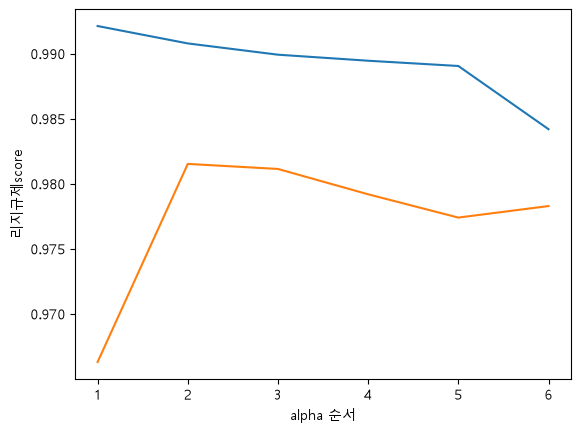

In [1614]:
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.show()

In [1615]:
ridge = Ridge(alpha=0.01)
ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)

train정확도 :  0.9907820655909816
test정확도 :  0.9815218258397003


In [1605]:
# degree = 2 / 특성을 9개로 변경해서 예측 
#데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)
#데이터 예측
predict = lr.predict(test_poly)
print("무게예측 : ",predict)
#데이터 검증 , 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)


무게예측 :  [ -20.11587172  465.81322384  265.77200315  109.87499315  127.09495993
 1068.7007113   315.85885749  201.93033404 3301.62626118  101.88914831
 3146.68184515  -40.22447253 -219.18204051  673.68594277]
train정확도 :  0.999528689807397
test정확도 :  -6.786696920351177
